In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors

plt.rcParams["font.family"] = "Arial"
%matplotlib inline

from utils.data_processing import combine_feature_importances
from additives_microbiota.plotting import process_string, process_string_pretty_vars

In [2]:
output_dir = "ml_outputs"
extremes_type = "low_high"  # "quintiles"
clr_scoring_type = "auroc"  # "auprc"

In [3]:
# def plot_auroc_boxplots(
#     auroc_data,
#     ax=None,
#     figsize=(6, 4),
#     title=None,
#     sort_by_median=False,
#     x_label=None,
# ):
#     """
#     Create horizontal boxplots comparing AUROC scores across features using seaborn.
#     """
#     # Rename fruits_minus_fast_food to (fruits) - (fast_food) before plotting
#     auroc_data = {
#         ("(" + key.replace("_minus_", ") - (").replace("_fg_eaten", "") + ")"): value
#         for key, value in auroc_data.items()
#     }

#     if ax is None:
#         _, ax = plt.subplots(figsize=figsize)

#     # Convert to long format for seaborn
#     df = pd.DataFrame(auroc_data)

#     # Sort columns by median values if requested
#     if sort_by_median:
#         medians = df.median().sort_values(ascending=False)
#         df = df[medians.index]

#     df_long = df.melt(var_name="Feature", value_name="AUROC")

#     df_long["feature_type"] = df_long["Feature"].apply(
#         lambda x: (
#             "Minus Fast Food"
#             if "- (fast_food)" in x
#             else (
#                 "Fast Food"
#                 if "(fast_food)" == x
#                 else "Additive" if "-" in x else "Reference"
#             )
#         )
#     )

#     # Custom color palette: green for reference, orange for fast food, lightblue for additives
#     custom_palette = {
#         "Minus Fast Food": "indianred",
#         "Reference": "lightgreen",
#         "Fast Food": "orange",
#         "Additive": "lightblue",
#     }

#     sns.boxplot(
#         data=df_long,
#         x="AUROC",
#         y="Feature",
#         orient="h",
#         hue="feature_type",
#         palette=custom_palette,
#         whis=1.5,
#         width=0.4,
#         fliersize=2,
#         linewidth=0.5,
#         ax=ax,
#         legend=False,
#     )

#     # Customize plot
#     ax.set_xlabel(x_label)
#     if title:
#         ax.set_title(title, fontsize=10)
#     ax.grid(False)
#     ax.set_ylabel("")

#     # Process feature names for readability
#     ax.set_yticks(range(len(df.columns)))
#     ax.set_yticklabels(
#         [
#             (
#                 process_string(col.replace("(", "").replace(")", ""))
#                 if " - " not in col
#                 else process_string(col)
#             )
#             for col in df.columns
#         ]
#     )

#     sns.despine()

In [4]:
def plot_auroc_boxplots(
    auroc_data,
    ax=None,
    figsize=(6, 4),
    title=None,
    sort_by_median=False,
    x_label=None,
):
    """
    Create horizontal boxplots comparing AUROC scores across features using seaborn.
    """

    if ax is None:
        _, ax = plt.subplots(figsize=figsize)

    # Convert to long format for seaborn
    df = pd.DataFrame(auroc_data)

    # Sort columns by median values if requested
    if sort_by_median:
        medians = df.median().sort_values(ascending=False)
        df = df[medians.index]

    df_long = df.melt(var_name="Feature", value_name="AUROC")

    df_long["feature_type"] = df_long["Feature"].apply(
        lambda x: (
            "Minus Fast Food"
            if "minus_fast_food" in x
            else (
                "Fast Food"
                if "fast_food" in x
                else "Additive" if "minus" in x else "Reference"
            )
        )
    )

    # Custom color palette: green for reference, orange for fast food, lightblue for additives
    custom_palette = {
        "Minus Fast Food": "indianred",
        "Reference": "lightgreen",
        "Fast Food": "orange",
        "Additive": "lightblue",
    }

    sns.boxplot(
        data=df_long,
        x="AUROC",
        y="Feature",
        orient="h",
        hue="feature_type",
        palette=custom_palette,
        whis=1.5,
        width=0.4,
        fliersize=2,
        linewidth=0.5,
        ax=ax,
        legend=False,
    )

    # Customize plot
    ax.set_xlabel(x_label)
    if title:
        ax.set_title(title, fontsize=10)
    ax.grid(False)
    ax.set_ylabel("")

    # Process feature names for readability
    ax.set_yticks(range(len(df.columns)))
    ax.set_yticklabels([process_string_pretty_vars(col) for col in df.columns])

    sns.despine()

## Classifier Results

In [5]:
clr_res = pd.read_csv(
    f"{output_dir}/clr_res_{extremes_type}_{clr_scoring_type}.csv", index_col=0
)
clr_res = clr_res.drop(
    columns=[
        "HEI_minus_other_additives",
        "fruits_minus_other_additives",
        "vegetables_minus_other_additives",
    ]
)
clr_res.head()

,HEI_minus_thickeners_stabilizers_emulsifiers_gelling_agents,HEI_minus_sweeteners_glazing_agents,HEI_minus_preservatives_antioxidants,HEI_minus_ph_regulators_anti_caking_leavening_agents,HEI_minus_flavor_enhancers,HEI_minus_colorants,HEI_minus_Mixture1,HEI_minus_Mixture2,HEI_minus_Mixture3,HEI_minus_fast_food,...,vegetables_minus_colorants,vegetables_minus_Mixture1,vegetables_minus_Mixture2,vegetables_minus_Mixture3,vegetables_minus_fast_food,vegetables_minus_total_additive_intake,HEI,fruits_fg_eaten,vegetables_fg_eaten,fast_food_fg_eaten
0,0.741774,0.808413,0.805914,0.838401,0.714286,0.804665,0.830487,0.775094,0.810496,0.872970,...,0.783840,0.837568,0.871720,0.749271,0.865473,0.827988,0.838817,0.743024,0.745523,0.721783
1,0.819242,0.822990,0.833819,0.794669,0.776760,0.821324,0.787172,0.837568,0.785923,0.841733,...,0.756768,0.748438,0.819658,0.792586,0.856726,0.830487,0.809663,0.697626,0.766347,0.735110
2,0.802999,0.840900,0.793419,0.777176,0.722616,0.857976,0.760933,0.748438,0.822574,0.804665,...,0.793836,0.830071,0.841733,0.821324,0.815910,0.827988,0.817160,0.701791,0.841316,0.717618
3,0.840067,0.854644,0.818409,0.825906,0.856726,0.844232,0.858392,0.801333,0.822990,0.836735,...,0.764265,0.783424,0.795918,0.753853,0.851312,0.808413,0.827155,0.651395,0.737609,0.769679
4,0.790087,0.818825,0.812995,0.871720,0.719284,0.808413,0.870054,0.830487,0.821741,0.870471,...,0.825489,0.837151,0.794252,0.692212,0.899625,0.778842,0.839650,0.699292,0.750521,0.806331


In [6]:
clr_res.median()

HEI_minus_thickeners_stabilizers_emulsifiers_gelling_agents           0.772387
HEI_minus_sweeteners_glazing_agents                                   0.822990
HEI_minus_preservatives_antioxidants                                  0.783840
HEI_minus_ph_regulators_anti_caking_leavening_agents                  0.838192
HEI_minus_flavor_enhancers                                            0.787380
HEI_minus_colorants                                                   0.839025
HEI_minus_Mixture1                                                    0.801958
HEI_minus_Mixture2                                                    0.825073
HEI_minus_Mixture3                                                    0.818409
HEI_minus_fast_food                                                   0.842566
HEI_minus_total_additive_intake                                       0.796543
fruits_minus_thickeners_stabilizers_emulsifiers_gelling_agents        0.747605
fruits_minus_sweeteners_glazing_agents              

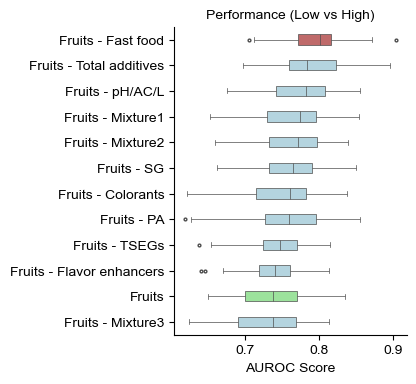

In [7]:
plot_auroc_boxplots(
    clr_res[[i for i in clr_res.columns if "fruit" in i]],
    title=(
        "Performance (Low vs High)"
        if extremes_type == "low_high"
        else "Performance (Quintiles)"
    ),
    sort_by_median=True,
    figsize=(3, 4),
    x_label="AUROC Score" if clr_scoring_type == "auroc" else "AUPRC Score",
)

plt.savefig(
    "../figures/ml_results/clr_res_fruit_boxplot.png", dpi=300, bbox_inches="tight"
)

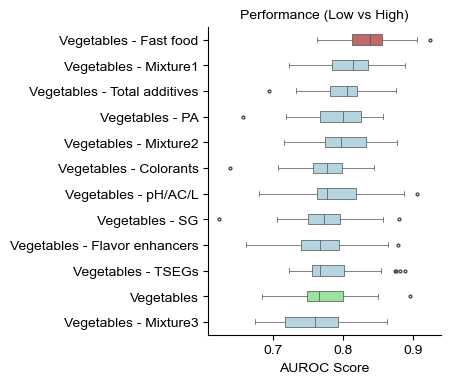

In [8]:
plot_auroc_boxplots(
    clr_res[[i for i in clr_res.columns if "vegetables" in i]],
    title=(
        "Performance (Low vs High)"
        if extremes_type == "low_high"
        else "Performance (Quintiles)"
    ),
    sort_by_median=True,
    figsize=(3, 4),
    x_label="AUROC Score" if clr_scoring_type == "auroc" else "AUPRC Score",
)
# print(clr_res["vegetables_fg_eaten"].describe())

plt.savefig(
    "../figures/ml_results/clr_res_vegetables_boxplot.png", dpi=300, bbox_inches="tight"
)

In [9]:
clr_res[[i for i in clr_res.columns if "vegetables" in i]].describe().round(2)

,vegetables_minus_thickeners_stabilizers_emulsifiers_gelling_agents,vegetables_minus_sweeteners_glazing_agents,vegetables_minus_preservatives_antioxidants,vegetables_minus_ph_regulators_anti_caking_leavening_agents,vegetables_minus_flavor_enhancers,vegetables_minus_colorants,vegetables_minus_Mixture1,vegetables_minus_Mixture2,vegetables_minus_Mixture3,vegetables_minus_fast_food,vegetables_minus_total_additive_intake,vegetables_fg_eaten
count,50.00,50.00,50.00,50.00,50.00,50.00,50.00,50.00,50.00,50.00,50.00,50.00
mean,0.78,0.77,0.79,0.79,0.77,0.78,0.81,0.80,0.76,0.83,0.80,0.77
std,0.04,0.05,0.04,0.05,0.05,0.04,0.04,0.04,0.05,0.04,0.03,0.04
min,0.72,0.62,0.66,0.68,0.66,0.64,0.72,0.71,0.67,0.76,0.69,0.68
25%,0.76,0.75,0.77,0.76,0.74,0.76,0.78,0.77,0.72,0.81,0.78,0.75
50%,0.77,0.77,0.80,0.78,0.77,0.78,0.81,0.80,0.76,0.84,0.81,0.76
75%,0.80,0.80,0.82,0.82,0.79,0.80,0.84,0.83,0.79,0.86,0.82,0.80
max,0.89,0.88,0.86,0.91,0.88,0.84,0.89,0.88,0.86,0.93,0.88,0.90


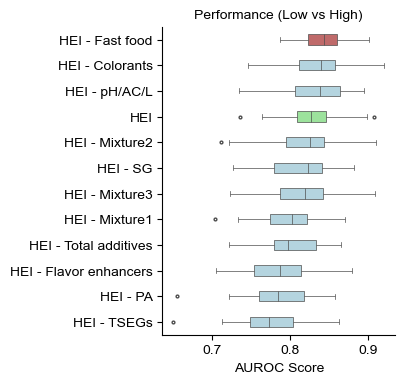

In [10]:
plot_auroc_boxplots(
    clr_res[[i for i in clr_res.columns if "HEI" in i]],
    title=(
        "Performance (Low vs High)"
        if extremes_type == "low_high"
        else "Performance (Quintiles)"
    ),
    sort_by_median=True,
    figsize=(3, 4),
    x_label="AUROC Score" if clr_scoring_type == "auroc" else "AUPRC Score",
)
plt.savefig(
    "../figures/ml_results/clr_res_HEI_boxplot.png", dpi=300, bbox_inches="tight"
)

In [11]:
clr_res[[i for i in clr_res.columns if "HEI" in i]].describe().round(2)

,HEI_minus_thickeners_stabilizers_emulsifiers_gelling_agents,HEI_minus_sweeteners_glazing_agents,HEI_minus_preservatives_antioxidants,HEI_minus_ph_regulators_anti_caking_leavening_agents,HEI_minus_flavor_enhancers,HEI_minus_colorants,HEI_minus_Mixture1,HEI_minus_Mixture2,HEI_minus_Mixture3,HEI_minus_fast_food,HEI_minus_total_additive_intake,HEI
count,50.00,50.00,50.00,50.00,50.00,50.00,50.00,50.00,50.00,50.00,50.00,50.00
mean,0.78,0.81,0.79,0.83,0.78,0.83,0.80,0.82,0.81,0.84,0.80,0.83
std,0.04,0.04,0.04,0.04,0.04,0.04,0.03,0.04,0.04,0.03,0.04,0.04
min,0.65,0.73,0.66,0.73,0.71,0.75,0.70,0.71,0.72,0.79,0.72,0.74
25%,0.75,0.78,0.76,0.81,0.75,0.81,0.77,0.79,0.79,0.82,0.78,0.81
50%,0.77,0.82,0.78,0.84,0.79,0.84,0.80,0.83,0.82,0.84,0.80,0.83
75%,0.80,0.84,0.82,0.86,0.81,0.86,0.82,0.84,0.84,0.86,0.83,0.85
max,0.86,0.88,0.86,0.89,0.88,0.92,0.87,0.91,0.91,0.90,0.87,0.91


### Fast food only

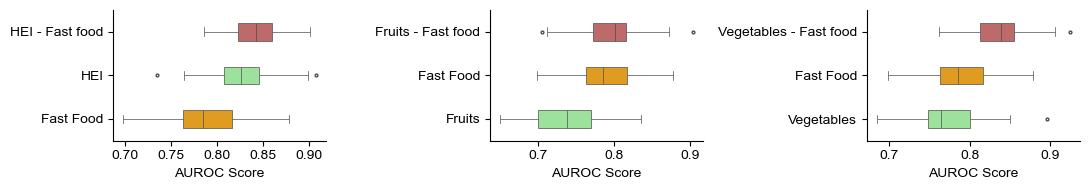

In [12]:
fig, ax = plt.subplots(ncols=3, figsize=(11, 2))

plot_auroc_boxplots(
    clr_res[["HEI", "HEI_minus_fast_food", "fast_food_fg_eaten"]],
    title="",
    sort_by_median=True,
    ax=ax[0],
    x_label="AUROC Score" if clr_scoring_type == "auroc" else "AUPRC Score",
)
plot_auroc_boxplots(
    clr_res[["fruits_fg_eaten", "fruits_minus_fast_food", "fast_food_fg_eaten"]],
    title="",
    sort_by_median=True,
    ax=ax[1],
    x_label="AUROC Score" if clr_scoring_type == "auroc" else "AUPRC Score",
)
plot_auroc_boxplots(
    clr_res[
        ["vegetables_fg_eaten", "vegetables_minus_fast_food", "fast_food_fg_eaten"]
    ],
    title="",
    sort_by_median=True,
    ax=ax[2],
    x_label="AUROC Score" if clr_scoring_type == "auroc" else "AUPRC Score",
)
plt.tight_layout()
plt.savefig(
    "../figures/ml_results/clr_res_fast_food_only.png", dpi=300, bbox_inches="tight"
)

## For Regression

In [13]:
def plot_spearman_correlations(df, title_suffix="", figsize=(6, 4), ax=None):

    df = df.reindex(columns=df.median().sort_values(ascending=False).index)

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)

    colors = []
    for col in df.columns:
        if col in ["HEI", "vegetables_fg_eaten", "fruits_fg_eaten"]:
            colors.append("lightgreen")
        elif col == "fast_food_fg_eaten":
            colors.append("orange")
        elif "fast_food" in col and "minus" in col:
            colors.append("indianred")
        else:
            colors.append("lightblue")

    # Transform column names with parentheses
    # df = df.rename(
    #     columns=lambda x: "("
    #     + x.replace("_minus_", ") - (").replace("_fg_eaten", "")
    #     + ")"
    # )
    df = df.rename(columns=lambda x: process_string_pretty_vars(x))
    sns.boxplot(
        data=df,
        palette=colors,
        width=0.4,
        linewidth=0.5,
        fliersize=2,
        orient="h",
        ax=ax,
    )
    # ax.set_yticks(ax.get_yticks())
    # ax.set_yticklabels(
    #     [
    #         (
    #             process_string(col.replace("(", "").replace(")", ""))
    #             if " - " not in col
    #             else process_string(col)
    #         )
    #         for col in df.columns
    #     ]
    # )
    ax.set_xlabel("Spearman Correlation")
    ax.set_title(f"{title_suffix}")
    ax.grid(axis="x", linestyle=":", alpha=0.7)
    sns.despine(ax=ax)

(50, 13)


,fruits_fg_eaten,fruits_minus_preservatives_antioxidants,fruits_minus_thickeners_stabilizers_emulsifiers_gelling_agents,fruits_minus_colorants,fruits_minus_ph_regulators_anti_caking_leavening_agents,fruits_minus_sweeteners_glazing_agents,fruits_minus_flavor_enhancers,fruits_minus_total_additive_intake,fruits_minus_Mixture1,fruits_minus_Mixture2,fruits_minus_Mixture3,fast_food_fg_eaten,fruits_minus_fast_food
0,0.207037,0.179535,0.260760,0.280430,0.256717,0.259299,0.134084,0.292173,0.208832,0.243725,0.168540,0.276123,0.357957
1,0.269181,0.248358,0.378894,0.344192,0.359189,0.377964,0.232651,0.423910,0.376002,0.392604,0.294839,0.277622,0.437838
2,0.271714,0.291652,0.270402,0.249195,0.267604,0.261799,0.252577,0.302782,0.258675,0.307966,0.165295,0.269408,0.327073
3,0.137470,0.167276,0.291664,0.245955,0.272346,0.283835,0.153968,0.323697,0.233381,0.214190,0.280070,0.324339,0.351891
4,0.215090,0.314053,0.317652,0.261371,0.310834,0.271893,0.222125,0.392245,0.273154,0.249955,0.290232,0.222881,0.392832


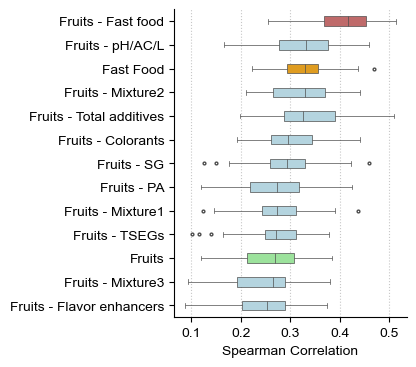

In [14]:
spr_corrs_main_var_fruits = pd.read_csv(
    f"{output_dir}/spr_corrs_main_var_fruits.csv", index_col=0
)

spr_corrs_main_var_fruits = spr_corrs_main_var_fruits.drop(
    columns=["fruits_minus_other_additives"]
)

print(spr_corrs_main_var_fruits.shape)
plot_spearman_correlations(spr_corrs_main_var_fruits, title_suffix="", figsize=(3, 4))

plt.savefig(
    "../figures/ml_results/spr_corrs_main_var_fruits.png", dpi=300, bbox_inches="tight"
)


spr_corrs_main_var_fruits.head()

(50, 13)


,vegetables_fg_eaten,vegetables_minus_preservatives_antioxidants,vegetables_minus_thickeners_stabilizers_emulsifiers_gelling_agents,vegetables_minus_colorants,vegetables_minus_ph_regulators_anti_caking_leavening_agents,vegetables_minus_sweeteners_glazing_agents,vegetables_minus_flavor_enhancers,vegetables_minus_total_additive_intake,vegetables_minus_Mixture1,vegetables_minus_Mixture2,vegetables_minus_Mixture3,fast_food_fg_eaten,vegetables_minus_fast_food
0,0.361639,0.261482,0.412544,0.378606,0.348496,0.328623,0.409757,0.345417,0.338905,0.392633,0.336549,0.276123,0.305724
1,0.398375,0.361427,0.367967,0.431287,0.412745,0.308780,0.352784,0.454937,0.375243,0.413499,0.307636,0.277622,0.354595
2,0.327448,0.343097,0.327239,0.299136,0.378826,0.233747,0.239632,0.302873,0.394721,0.364460,0.212862,0.269408,0.408746
3,0.407707,0.394010,0.281930,0.428770,0.356903,0.306022,0.202659,0.338381,0.322614,0.368559,0.288869,0.324339,0.416136
4,0.275214,0.300087,0.303952,0.202195,0.316665,0.291052,0.298704,0.269514,0.310125,0.325451,0.246060,0.222881,0.326412


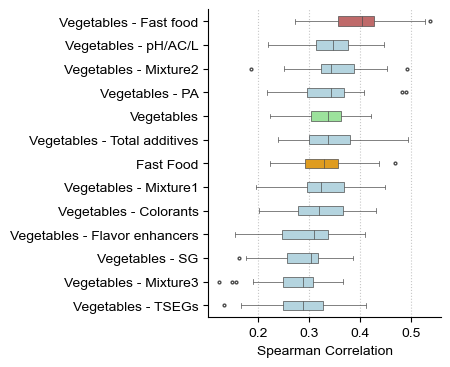

In [15]:
spr_corrs_main_var_vegetables = pd.read_csv(
    f"{output_dir}/spr_corrs_main_var_vegetables.csv", index_col=0
)
spr_corrs_main_var_vegetables = spr_corrs_main_var_vegetables.drop(
    columns=["vegetables_minus_other_additives"]
)
print(spr_corrs_main_var_vegetables.shape)
plot_spearman_correlations(
    spr_corrs_main_var_vegetables, title_suffix="", figsize=(3, 4)
)

plt.savefig(
    "../figures/ml_results/spr_corrs_main_var_vegetables.png",
    dpi=300,
    bbox_inches="tight",
)

spr_corrs_main_var_vegetables.head()

(50, 13)


,HEI,HEI_minus_preservatives_antioxidants,HEI_minus_thickeners_stabilizers_emulsifiers_gelling_agents,HEI_minus_colorants,HEI_minus_ph_regulators_anti_caking_leavening_agents,HEI_minus_sweeteners_glazing_agents,HEI_minus_flavor_enhancers,HEI_minus_total_additive_intake,HEI_minus_Mixture1,HEI_minus_Mixture2,HEI_minus_Mixture3,fast_food_fg_eaten,HEI_minus_fast_food
0,0.357554,0.217016,0.274800,0.323375,0.305234,0.270108,0.382549,0.351029,0.236097,0.288231,0.256104,0.276123,0.374371
1,0.474588,0.310644,0.367030,0.482749,0.373741,0.462777,0.394824,0.502973,0.382563,0.463272,0.428371,0.277622,0.443877
2,0.426825,0.320960,0.371121,0.346940,0.380231,0.371060,0.343519,0.346599,0.327714,0.425142,0.316508,0.269408,0.458818
3,0.468379,0.342964,0.425678,0.404201,0.430402,0.339967,0.336160,0.460009,0.369229,0.435479,0.390767,0.324339,0.447559
4,0.265617,0.239554,0.306288,0.285734,0.321274,0.232541,0.293347,0.341472,0.238604,0.271061,0.223059,0.222881,0.351276


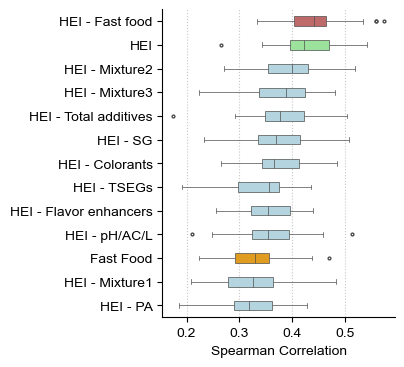

In [16]:
spr_corrs_main_var_HEI = pd.read_csv(
    f"{output_dir}/spr_corrs_main_var_HEI.csv", index_col=0
)
spr_corrs_main_var_HEI = spr_corrs_main_var_HEI.drop(
    columns=["HEI_minus_other_additives"]
)
print(spr_corrs_main_var_HEI.shape)
plot_spearman_correlations(spr_corrs_main_var_HEI, title_suffix="", figsize=(3, 4))

plt.savefig(
    "../figures/ml_results/spr_corrs_main_var_HEI.png", dpi=300, bbox_inches="tight"
)
spr_corrs_main_var_HEI.head()

## For Fast Food only (Regression)

In [17]:
# mini_reg_res = pd.merge(
#     spr_corrs_main_var_fruits[["fruits_fg_eaten", "(fruits) - (fast_food)"]],
#     spr_corrs_main_var_vegetables[
#         ["vegetables_fg_eaten", "(vegetables) - (fast_food)"]
#     ],
#     left_index=True,
#     right_index=True,
# ).merge(
#     spr_corrs_main_var_HEI[["HEI", "(HEI) - (fast_food)"]],
#     left_index=True,
#     right_index=True,
# )

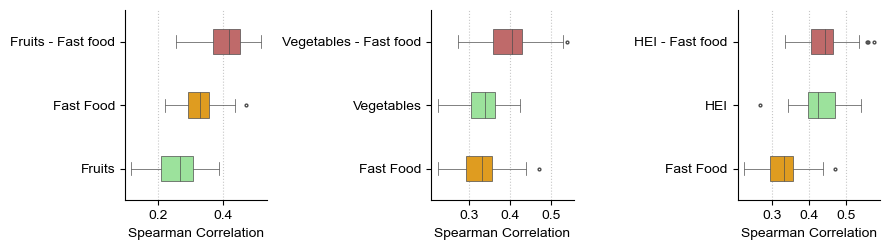

In [18]:
fig, ax = plt.subplots(ncols=3, nrows=1, figsize=(9, 2.6))

plot_spearman_correlations(
    spr_corrs_main_var_fruits[
        ["fruits_fg_eaten", "fruits_minus_fast_food", "fast_food_fg_eaten"]
    ],
    title_suffix="",
    ax=ax[0],
)
plot_spearman_correlations(
    spr_corrs_main_var_vegetables[
        ["vegetables_fg_eaten", "vegetables_minus_fast_food", "fast_food_fg_eaten"]
    ],
    title_suffix="",
    ax=ax[1],
)
plot_spearman_correlations(
    spr_corrs_main_var_HEI[["HEI", "HEI_minus_fast_food", "fast_food_fg_eaten"]],
    title_suffix="",
    ax=ax[2],
)
plt.tight_layout()
plt.savefig(
    "../figures/ml_results/reg_res_fast_food_only.png", dpi=300, bbox_inches="tight"
)

In [19]:
print(
    spr_corrs_main_var_fruits[
        [
            "fruits_fg_eaten",
            "fruits_minus_fast_food",
            "fast_food_fg_eaten",
        ]
    ]
    .describe()
    .round(2)
)

print(
    spr_corrs_main_var_vegetables[
        [
            "vegetables_fg_eaten",
            "vegetables_minus_fast_food",
            "fast_food_fg_eaten",
        ]
    ]
    .describe()
    .round(2)
)

print(
    spr_corrs_main_var_HEI[
        [
            "HEI",
            "HEI_minus_fast_food",
            "fast_food_fg_eaten",
        ]
    ]
    .describe()
    .round(2)
)

       fruits_fg_eaten  fruits_minus_fast_food  fast_food_fg_eaten
count            50.00                   50.00               50.00
mean              0.26                    0.41                0.33
std               0.07                    0.06                0.05
min               0.12                    0.25                0.22
25%               0.21                    0.37                0.29
50%               0.27                    0.42                0.33
75%               0.31                    0.45                0.36
max               0.39                    0.51                0.47
       vegetables_fg_eaten  vegetables_minus_fast_food  fast_food_fg_eaten
count                50.00                       50.00               50.00
mean                  0.33                        0.40                0.33
std                   0.05                        0.06                0.05
min                   0.22                        0.27                0.22
25%                   

## Combinatorial Analysis

In [20]:
clr_combo_res = pd.read_csv(
    f"{output_dir}/ml_res_clr_low_high_combo.csv", index_col=0
).T
clr_combo_res.index = [
    (
        tuple(idx.strip("()").split(", "))
        if isinstance(idx, str) and idx.startswith("(")
        else idx
    )
    for idx in clr_combo_res.index
]

clr_combo_res.sort_values(by="mean_auroc", ascending=False)

,mean_auroc
"('thickeners_stabilizers_emulsifiers_gelling_agents', 'ph_regulators_anti_caking_leavening_agents', 'colorants')",0.677665
"('thickeners_stabilizers_emulsifiers_gelling_agents', 'preservatives_antioxidants', 'ph_regulators_anti_caking_leavening_agents', 'colorants')",0.674049
"('preservatives_antioxidants', 'ph_regulators_anti_caking_leavening_agents', 'colorants')",0.672381
"('thickeners_stabilizers_emulsifiers_gelling_agents', 'preservatives_antioxidants', 'ph_regulators_anti_caking_leavening_agents', 'sweeteners_glazing_agents', 'colorants')",0.668222
"('thickeners_stabilizers_emulsifiers_gelling_agents', 'ph_regulators_anti_caking_leavening_agents')",0.666739
"('thickeners_stabilizers_emulsifiers_gelling_agents', 'preservatives_antioxidants', 'ph_regulators_anti_caking_leavening_agents', 'sweeteners_glazing_agents')",0.666456
"('ph_regulators_anti_caking_leavening_agents', 'sweeteners_glazing_agents')",0.663032
"('preservatives_antioxidants', 'ph_regulators_anti_caking_leavening_agents')",0.662024
"('thickeners_stabilizers_emulsifiers_gelling_agents', 'ph_regulators_anti_caking_leavening_agents', 'sweeteners_glazing_agents', 'colorants')",0.659938
"('preservatives_antioxidants', 'ph_regulators_anti_caking_leavening_agents', 'sweeteners_glazing_agents')",0.655731


In [21]:
def plot_auroc_additive_performance(
    ml_res, variables=None, short_names=None, figsize=(14, 10)
):
    """
    Create a visualization with scatterplot showing additive combinations and horizontal bars showing AUROC performance.

    Parameters:
    -----------
    ml_res : dict
        Dictionary with tuples of variable names as keys and AUROC values as values
    variables : list, optional
        List of original variable names
    short_names : dict, optional
        Dictionary mapping original variable names to shorter display names
    figsize : tuple, optional
        Figure size for the plot

    Returns:
    --------
    fig : matplotlib figure
        Figure containing the visualization
    """

    # If variables not provided, extract them from ml_res keys
    if variables is None:
        variables = sorted(list(set(var for combo in ml_res.keys() for var in combo)))

    # If short_names not provided, create abbreviated versions
    if short_names is None:
        short_names = {}
        for var in variables:
            parts = var.split("_")
            short_name = "_".join([p[:5] for p in parts])
            short_names[var] = short_name

    # Get short variable names for display
    short_var_names = [short_names[var] for var in variables]

    # Sort combinations by AUROC value (descending)
    sorted_combos = sorted(ml_res.items(), key=lambda x: x[1], reverse=True)

    # Limit to top 25 combinations (or fewer if there are less)
    top_n = min(25, len(sorted_combos))
    sorted_combos = sorted_combos[:top_n]

    # Create figure and axis
    fig, ax = plt.subplots(figsize=figsize)

    # Define colors for the visualization
    # We'll use YlGnBu-like colors for the bars
    colors = [
        "#FFFFCC",
        "#C7E9B4",
        "#7FCDBB",
        "#41B6C4",
        "#1D91C0",
        "#225EA8",
        "#0C2C84",
    ]
    cmap = mcolors.LinearSegmentedColormap.from_list("colormap", colors[::-1], N=256)

    # Get AUROC values for normalization
    auroc_values = [auroc for _, auroc in sorted_combos]
    min_auroc = min(auroc_values) * 0.98
    max_auroc = max(auroc_values) * 1.01

    # Create y positions for the bars
    y_positions = np.arange(len(sorted_combos))

    # Set up plot area - reserve first 50% for scatter dots, next 30% for bars, 20% for values
    scatter_width = 0.5
    bar_section_width = 0.3
    bar_start = scatter_width

    # Set x-axis limits - total plot width is 1.0
    plot_min = 0
    plot_max = 1.0

    # Calculate positions for scatter dots (evenly spaced in the first 50% of the plot)
    dot_positions = np.linspace(
        plot_min + 0.05 * scatter_width, plot_min + 0.95 * scatter_width, len(variables)
    )

    # Calculate bar lengths - make them proportional to AUROC values but within the bar section
    # Start from a minimum value (~0.5) to ensure all bars are visible
    min_bar_display = 0.5  # Minimum display value

    # Scale the bar lengths to fit within the bar section
    bar_lengths = [
        (
            (val - min_auroc) / (max_auroc - min_auroc) * (1 - min_bar_display)
            + min_bar_display
        )
        * bar_section_width
        for val in auroc_values
    ]

    # Calculate normalized values for color mapping
    norm_values = [(val - min_auroc) / (max_auroc - min_auroc) for val in auroc_values]

    # Create bar colors based on AUROC values
    bar_colors = [cmap(norm) for norm in norm_values]

    # Prepare data for plotting
    labels = []  # Combination labels for y-axis

    # Draw bars for AUROC values
    for i, (combo, auroc) in enumerate(sorted_combos):
        # Draw the bar
        bar = ax.barh(
            y_positions[i],
            bar_lengths[i],
            left=bar_start,
            color=bar_colors[i],
            height=0.7,
            alpha=0.8,
        )

        # Add AUROC value to the right of the bar
        ax.text(
            bar_start + bar_lengths[i] + 0.01,
            y_positions[i],
            f"{auroc:.4f}",
            va="center",
            fontsize=9,
        )

        # Create label for this combination
        if len(combo) == 1:
            label = short_names[combo[0]]
        else:
            label = " + ".join([short_names[var] for var in combo])
        labels.append(label)

    # Now add scatter points to show which variables are in each combination
    for i, (combo, _) in enumerate(sorted_combos):
        # For each variable
        for j, var in enumerate(variables):
            if var in combo:
                # If variable is in the combination, add a filled circle
                ax.scatter(
                    dot_positions[j], y_positions[i], color="#1D91C0", s=120, zorder=3
                )
            else:
                # If variable is not in the combination, add an empty circle
                ax.scatter(
                    dot_positions[j],
                    y_positions[i],
                    color="#1D91C0",
                    s=120,
                    facecolors="none",
                    alpha=0.3,
                    zorder=2,
                )

    # Add variable names at the bottom of the plot
    for j, name in enumerate(short_var_names):
        ax.text(
            dot_positions[j],
            -1,
            name,
            rotation=45,
            ha="center",
            va="top",
            fontsize=10,
            fontweight="bold",
        )

    # Draw a vertical line between the scatter points and bars
    ax.axvline(x=bar_start, color="gray", linestyle="--", alpha=0.5, zorder=1)

    # Set y-ticks
    ax.set_yticks(y_positions)

    # Add combination labels to the left
    ax.set_yticklabels(labels)

    # Set x-axis limits
    ax.set_xlim(plot_min, plot_max)

    # Hide x-axis ticks and labels since we have custom layout
    ax.set_xticks([])
    ax.set_xticklabels([])

    # # Add titles and labels
    # ax.set_title(
    #     "Feature Combinations Ranked by AUROC Performance",
    #     fontsize=16,
    #     fontweight="bold",
    #     pad=20,
    # )

    # Add a legend for the bar scale (using ~ instead of ∝ symbol)
    scale_x = bar_start + bar_section_width * 0.5
    ax.text(
        scale_x,
        -1,
        # f"Bar length ~ AUROC: {min_auroc:.3f} - {max_auroc:.3f}",
        f"AUROC",
        ha="center",
        va="top",
        fontsize=9,
    )

    # Style the plot
    ax.grid(False)  # Remove grid entirely for cleaner look
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(False)

    # Add legend for the dots
    from matplotlib.lines import Line2D

    legend_elements = [
        Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            markerfacecolor="#1D91C0",
            markersize=10,
            label="Present",
        ),
        Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            markerfacecolor="none",
            markeredgecolor="#1D91C0",
            markersize=10,
            label="Absent",
            alpha=0.3,
        ),
    ]
    ax.legend(handles=legend_elements, loc="upper right", frameon=True, fontsize=10)

    # # Add subtitle explaining the visualization
    # plt.figtext(
    #     0.5,
    #     0.01,
    #     "Left: Feature presence in combinations. Right: Bars with length proportional to AUROC performance.",
    #     ha="left",
    #     fontsize=10,
    #     style="italic",
    # )

    plt.tight_layout(rect=[0, 0.03, 1, 0.97])

    # # Add textbox for full names and their short names in the top right corner
    # mapping_text = "\n\n".join(
    #     f"{full}: {short}" for full, short in short_names.items()
    # )
    # ax.text(
    #     1.4,
    #     0.98,
    #     mapping_text,
    #     transform=ax.transAxes,
    #     fontsize=12,
    #     verticalalignment="top",
    #     horizontalalignment="right",
    #     bbox=dict(facecolor="white", alpha=0.8, edgecolor="gray"),
    # )

    return fig

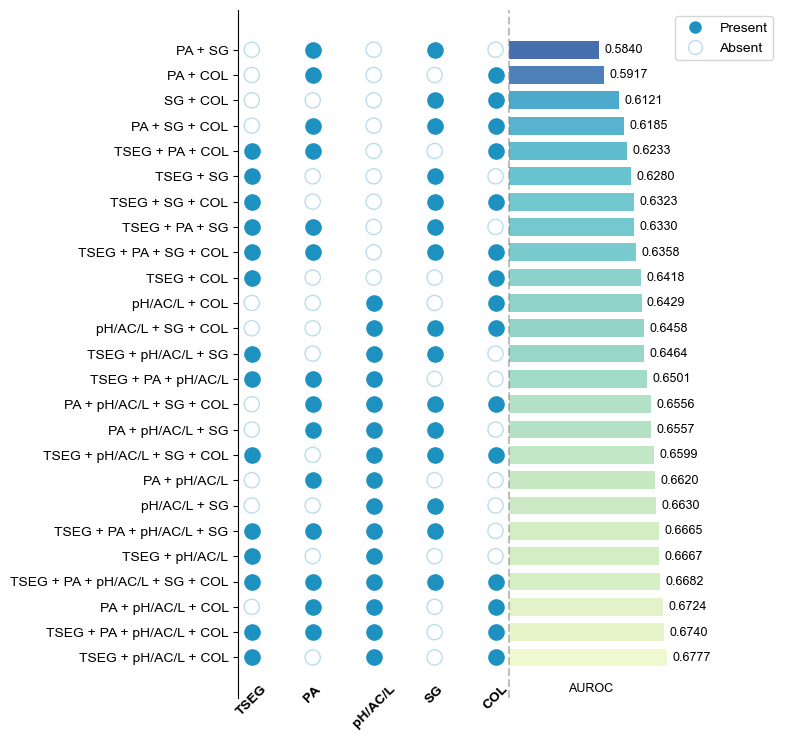

In [22]:
# Convert the pandas DataFrame to the dictionary format expected by the function
clr_combo_res_dict = {}
for idx, row in clr_combo_res.iterrows():
    # Extract the numeric value from the Series
    auroc_value = float(row.iloc[0])

    # Clean the tuple keys - remove any extra quotes
    cleaned_key = []
    for item in idx:
        # Remove any extra quotes from the string
        if isinstance(item, str):
            item = item.strip("'\"")
        cleaned_key.append(item)

    clr_combo_res_dict[tuple(cleaned_key)] = auroc_value

few_vars = [
    "thickeners_stabilizers_emulsifiers_gelling_agents",
    "preservatives_antioxidants",
    "ph_regulators_anti_caking_leavening_agents",
    "sweeteners_glazing_agents",
    "colorants",
]

short_names = {
    "thickeners_stabilizers_emulsifiers_gelling_agents": "TSEG",
    "preservatives_antioxidants": "PA",
    "ph_regulators_anti_caking_leavening_agents": "pH/AC/L",
    "sweeteners_glazing_agents": "SG",
    "colorants": "COL",
}

# Create the visualization with the converted dictionary
fig = plot_auroc_additive_performance(
    clr_combo_res_dict,  # Use the dictionary instead of the DataFrame
    few_vars,
    short_names,
    figsize=(8, 8),
)


plt.savefig("../figures/ml_results/clr_combo_res.png", dpi=300, bbox_inches="tight")
plt.show()

## Mixtures

In [23]:
mixture_combo_res = pd.read_csv(
    f"{output_dir}/ml_res_clr_mixtures_low_high_combo.csv", index_col=0
).T
mixture_combo_res.index = [
    (
        tuple(idx.strip("()").split(", "))
        if isinstance(idx, str) and idx.startswith("(")
        else idx
    )
    for idx in mixture_combo_res.index
]

mixture_combo_res.sort_values(by="mean_auroc", ascending=False)

,mean_auroc
"('Mixture1', 'Mixture2', 'Mixture3')",0.640733
"('Mixture1', 'Mixture2')",0.640458
"('Mixture1',,)",0.618417
"('Mixture2', 'Mixture3')",0.603140
"('Mixture2',,)",0.598384
"('Mixture1', 'Mixture3')",0.587655
"('Mixture3',,)",0.533562
